# 10 — Multiple Correspondence Analysis of Social Background
This notebook uses MCA to map how respondents' social-background categories (parents' and own education, sex and age group) cluster together, and then tests whether a respondent's position in that space is associated with traditional gender-role attitudes. The gender-role items are deliberately left out of the MCA, so the space describes social background only.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
from plotnine import *
import prince
import statsmodels.formula.api as smf
from stargazer.stargazer import Stargazer
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "code":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"
TABLES = PROJECT_ROOT / "output" / "tables"
FIGURES = PROJECT_ROOT / "output" / "figures"

df = pd.read_csv(DATA_PATH)
outcome = "traditional_gender_attitudes"

## 1. Active categorical variables

In [2]:
edu = {1: "Lower", 2: "Middle", 3: "Higher"}
age_order = ["21-29", "30-39", "40-49", "50-59", "60-69", "70+"]
cats = pd.DataFrame({
    "Mother": df["Q277R"].map(edu),
    "Father": df["Q278R"].map(edu),
    "Own edu": df["Q275R"].map(edu),
    "Sex": df["female"].map({0: "Male", 1: "Female"}),
    "Age": pd.cut(df["Q262"], bins=[20, 29, 39, 49, 59, 69, 120], labels=age_order).astype(object),
}).dropna()
print(f"Complete cases on the five active variables: N = {len(cats)}")
cats.head()

Complete cases on the five active variables: N = 1807


,Mother,Father,Own edu,Sex,Age
0,Lower,Lower,Higher,Female,30-39
2,Lower,Lower,Higher,Male,21-29
3,Lower,Lower,Higher,Female,30-39
5,Lower,Lower,Lower,Female,50-59
6,Lower,Lower,Lower,Female,70+


## 2. Running the MCA

In [3]:
mca = prince.MCA(n_components=5, n_iter=10, random_state=4002).fit(cats)

## 3. Inertia

In [4]:
inertia = mca.eigenvalues_summary
inertia.to_csv(TABLES / "mca_inertia.csv")
inertia

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.488,20.33%,20.33%
1,0.292,12.15%,32.47%
2,0.224,9.33%,41.80%
3,0.219,9.11%,50.91%
4,0.206,8.57%,59.48%


N = 1,807 respondents have complete data on all five variables. Dimension 1 (component 0) captures 20.3% of the inertia and Dimension 2 (component 1) 12.2%, so the first two dimensions together capture 32.5%. The remaining dimensions each add less than 10%, so we interpret only the first two.

## 4. Category coordinates and contributions

Coordinates place each category in the space; contributions show how much each category defines a dimension.

In [5]:
coords = mca.column_coordinates(cats).iloc[:, :2]
contribs = mca.column_contributions_.iloc[:, :2]
category_table = pd.concat([coords.set_axis(["Dim 1 coordinate", "Dim 2 coordinate"], axis=1),
                            contribs.set_axis(["Dim 1 contribution", "Dim 2 contribution"], axis=1)], axis=1)
category_table.index = category_table.index.str.replace("__", ": ")
category_table.to_csv(TABLES / "mca_category_coordinates_contributions.csv")
category_table.round(3)

,Dim 1 coordinate,Dim 2 coordinate,Dim 1 contribution,Dim 2 contribution
Mother: Higher,1.597,2.095,0.098,0.283
Mother: Lower,-0.546,0.025,0.084,0.000
Mother: Middle,1.037,-0.986,0.096,0.145
Father: Higher,1.448,1.520,0.122,0.226
Father: Lower,-0.637,0.093,0.101,0.004
Father: Middle,0.716,-1.082,0.053,0.202
Own edu: Higher,0.594,-0.087,0.076,0.003
Own edu: Lower,-1.290,0.479,0.117,0.027
Own edu: Middle,-0.307,-0.121,0.012,0.003
Sex: Female,-0.063,0.001,0.001,0.000


## 5. Biplot of Dimensions 1 and 2

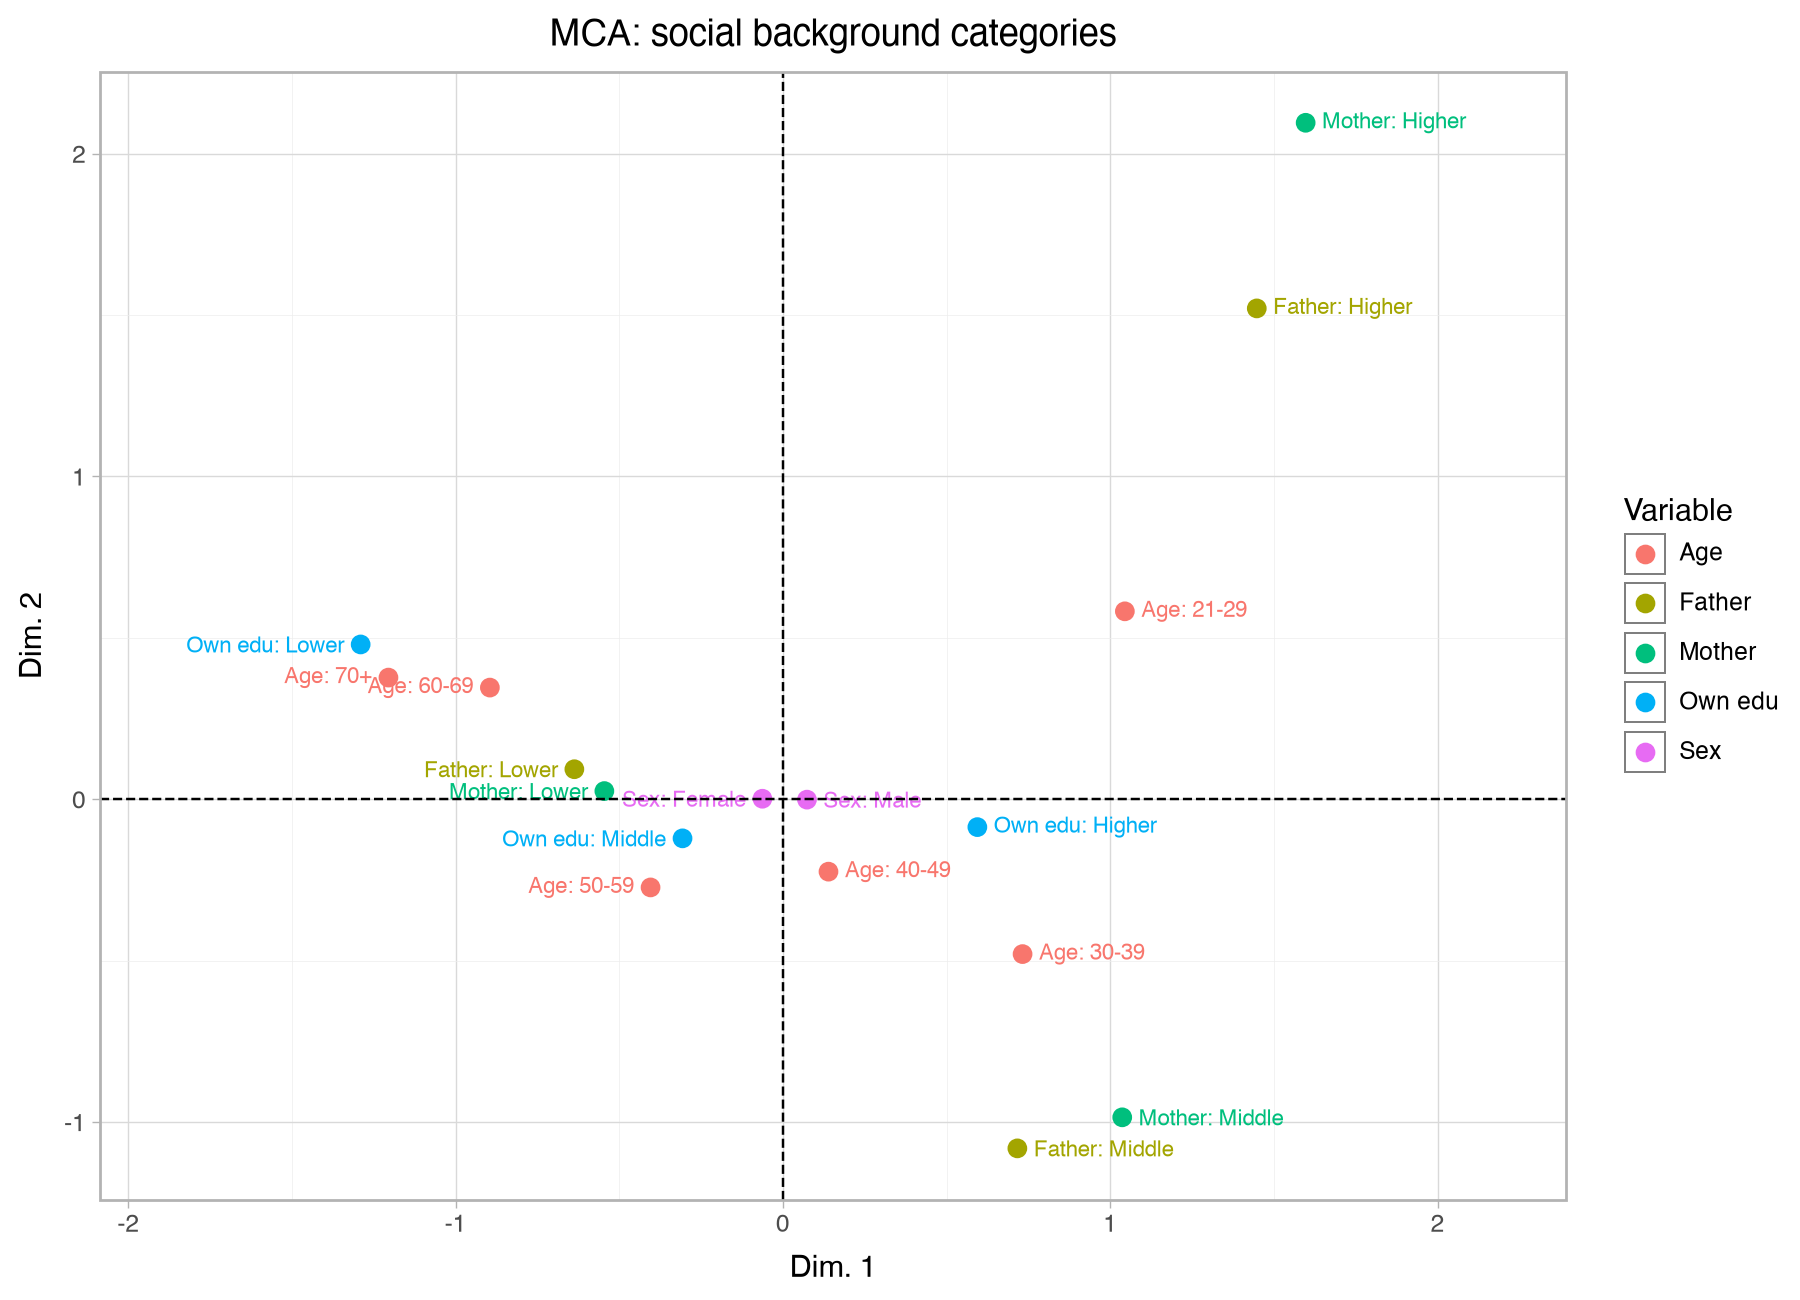

In [6]:
coords_plot = category_table.reset_index(names="category")
coords_plot["variable"] = coords_plot["category"].str.split(": ").str[0]

p = (
    ggplot(coords_plot, aes("Dim 1 coordinate", "Dim 2 coordinate", label="category", color="variable"))
    + geom_point(size=3)
    + geom_text(data=coords_plot[coords_plot["Dim 1 coordinate"] < 0], ha="right", nudge_x=-0.05,
                size=8, show_legend=False)
    + geom_text(data=coords_plot[coords_plot["Dim 1 coordinate"] >= 0], ha="left", nudge_x=0.05,
                size=8, show_legend=False)
    + geom_vline(xintercept=0, linetype="dashed")
    + geom_hline(yintercept=0, linetype="dashed")
    + scale_x_continuous(expand=(0.25, 0))
    + theme_light()
    + labs(x="Dim. 1", y="Dim. 2", color="Variable", title="MCA: social background categories")
    + theme(figure_size=(9, 6.5))
)
p.save(FIGURES / "mca_biplot.png", dpi=300, verbose=False)
p

**Dimension 1** runs from lower education and older age (left: own education Lower −1.290, age 70+ −1.205, both parents Lower) to higher education and youth (right: mother Higher 1.597, father Higher 1.448, age 21–29 1.045, own education Higher 0.594). It is a cultural-capital and generation axis: young, well-educated respondents from educated families sit on the right. **Dimension 2** is defined almost entirely by parents' education (mother Higher contributes 0.283, father Higher 0.226, father Middle 0.202, mother Middle 0.145) and separates families where parents had higher education (top) from those with middle education (bottom). Sex contributes almost nothing to either dimension (≤ 0.001), so men and women share the same social-background space.

## 6. Dimension scores and gender-role attitudes
We use each respondent's Dimension 1 and 2 scores as predictors. OLS is used because the outcome is an averaged 1–4 score that behaves like a continuous variable, not a yes/no or count outcome.

In [7]:
rows = mca.row_coordinates(cats).iloc[:, :2]
rows.columns = ["Dim1", "Dim2"]
reg_df = df[[outcome]].join(rows, how="inner").dropna()
mca_ols = smf.ols(f"{outcome} ~ Dim1 + Dim2", data=reg_df).fit()

sg = Stargazer([mca_ols])
sg.title("Traditional gender-role attitudes on MCA dimension scores")
sg.dependent_variable_name("Traditional gender-role attitudes")
sg.rename_covariates({"Dim1": "Dimension 1", "Dim2": "Dimension 2", "Intercept": "Intercept"})
(TABLES / "mca_ols_stargazer.html").write_text(sg.render_html())
print(f"N = {int(mca_ols.nobs)}")
sg

N = 1772


Stars mark p < .1 (\*), p < .05 (\*\*) and p < .01 (\*\*\*).

A one-unit increase in a respondent's Dimension 1 score is associated with a 0.226-point decrease in the gender-role score (p < .01), and a one-unit increase in Dimension 2 with a 0.058-point decrease (p < .05), ceteris paribus (N = 1,772). Respondents positioned towards youth and high cultural capital are therefore less traditional, and among them those whose parents had higher rather than middle education are slightly less traditional still. Together the two dimensions explain 8.4% of the variance (R² = 0.084).

## Summary

- MCA on mother's, father's and own education, sex and age group (N = 1,807).
- Dimension 1 (20.3% of inertia) contrasts older, less-educated respondents from less-educated families with young, educated respondents from educated families.
- Dimension 2 (12.2%) separates higher-educated from middle-educated parents; sex plays almost no role in either dimension.
- Both dimension scores predict less traditional attitudes (Dim 1 −0.226, p < .01; Dim 2 −0.058, p < .05; R² = 0.084).
- Consistent with a cultural-capital reading, gender-role attitudes follow a combined position of education and generation rather than parental education alone.